# Five-method nominal benchmark

**Author: Mohammad ALbaraj**

[Notebook index](README.md) · [Main project](../README.md)

Run cells from top to bottom. Saved results and fresh examples are labeled separately. Scientific source modules remain the authoritative implementation.


In [1]:
from pathlib import Path
import sys, json, csv
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Code

# Works when launched from the repository root or any notebook subdirectory.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'CITATION.cff').exists() and (p / 'all work').is_dir())
if str(ROOT / 'notebooks') not in sys.path:
    sys.path.insert(0, str(ROOT / 'notebooks'))
from notebook_support import (METHODS, ORIGINAL, NOMINAL, ROBUST, study, load_json,
    load_csv, show_table, show_source, source_index, load_runs, fitness_summary,
    convergence_plot, validation_rows, validation_summary, figures, file_links,
    show_figures, gallery, isolated_python, demo_source)
plt.rcParams.update({'figure.dpi': 100, 'font.size': 10})
print('Project loaded. Default cells do not launch full optimization campaigns.')


Project loaded. Default cells do not launch full optimization campaigns.


## Experiment contract
There are 150 main searches: five methods × 30 seeds × 3,264 unique evaluations. Initialization counts, duplicates are cached, and the last batch is truncated at the budget. Nominal uses six training cases; robust uses 30.


In [2]:
MODE='nominal'
BENCHMARK=NOMINAL if MODE=='nominal' else ROBUST
contract=load_json(BENCHMARK/'results/contract.json')
show_table([{'field':k,'value':v} for k,v in contract.items() if k not in ['configuration','code_sha256','training_cases','validation_cases']])
show_table([r for r in fitness_summary(ORIGINAL) if r['regime']==MODE])


field,value
budget,3264
seeds,"[11, 29, 47, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127]"
methods,"[""GA"", ""PSO"", ""CSO"", ""DSA"", ""CMA-ES""]"


method,regime,runs,best,median,mean,sample_sd,feasible
GA,nominal,30,0.0513596826213876,0.05226312547838116,0.05234592317298383,0.00047155332220080037,30
PSO,nominal,30,0.05103350348240746,0.052025843178989103,0.051917325210781524,0.00046374850992765847,30
CSO,nominal,30,0.05797834584155963,0.06714704781071607,0.06894582617207273,0.006431856988668625,30
DSA,nominal,30,0.05226800719584598,0.05702833085335258,0.05870858887815674,0.004588144239095514,30
CMA-ES,nominal,30,0.05226415044430983,0.052958784530325265,0.053037539135384566,0.0005636200006585569,30


## Convergence from raw evaluation ledgers
The band is the across-seed interquartile range, not a confidence band on future control performance.


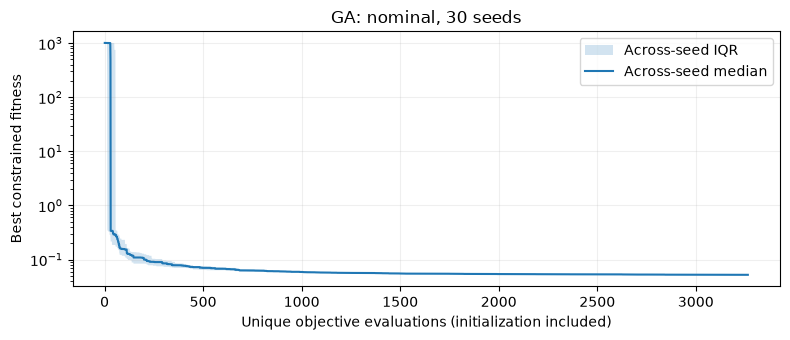

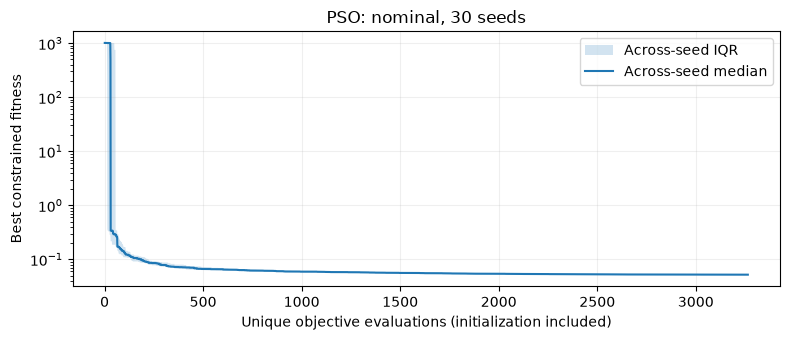

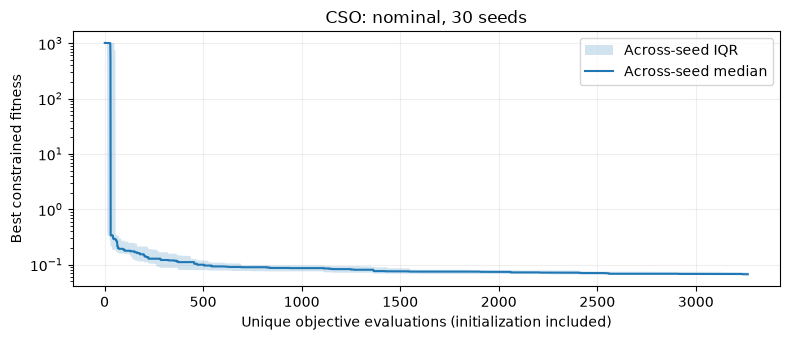

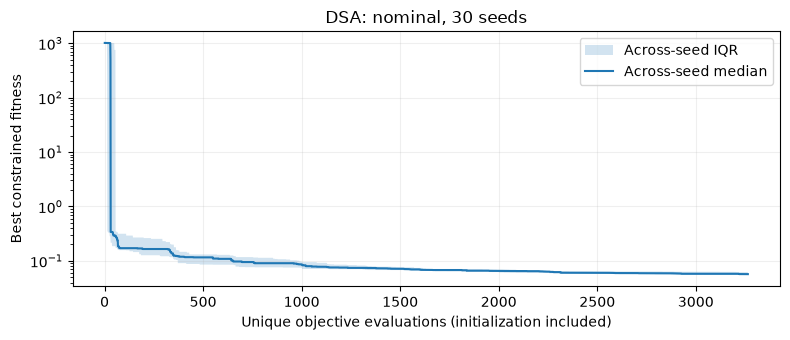

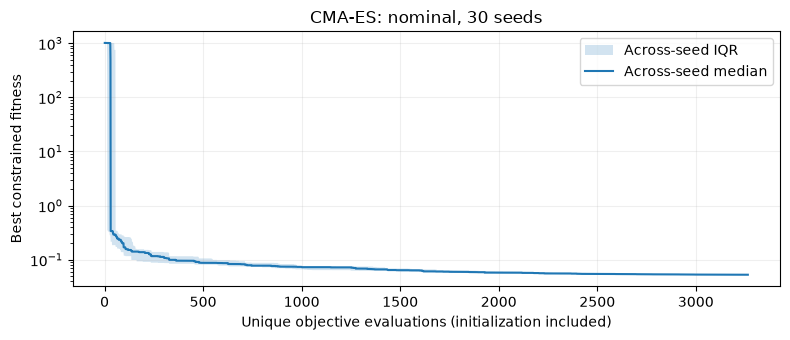

In [3]:
for method in ORIGINAL:
    convergence_plot(method,MODE)


## Selected controllers and statistical metadata
Selections use training fitness. The median representative is an actual run near the median, not a vector of median gains.


In [4]:
show_table(load_csv(BENCHMARK/'results/selected_candidates.csv'),limit=25)
display(Code(json.dumps(load_json(BENCHMARK/'results/statistics.json'),indent=2),language='json'))


method,selection,seed,fitness,single_axis_passes,combined_passes,held_out_passes
GA,best,102,0.0513596826213876,59,0,10
GA,median_representative,11,0.052276412343770014,60,0,7
PSO,best,107,0.05103350348240746,58,0,9
PSO,median_representative,105,0.05206902324768102,59,0,5
CSO,best,114,0.05797834584155963,60,0,7
CSO,median_representative,127,0.06677266609028382,60,0,10
DSA,best,117,0.05226800719584598,59,0,8
DSA,median_representative,47,0.05666513758123898,60,0,8
CMA-ES,best,47,0.05226415044430983,60,0,5
CMA-ES,median_representative,119,0.05290860909712142,60,0,5


{
  "friedman_statistic": 106.48000000000002,
  "friedman_asymptotic_p": 4.0971462283759373e-22,
  "within_seed_permutation_p": 4.999750012499375e-05,
  "permutations": 20000,
  "bootstrap_resamples": 10000,
  "bootstrap_seed": 7102026,
  "paired": true,
  "caveat": "Inference concerns optimizer randomness on this one fixed problem. Wilcoxon uses symmetric paired-difference null; intervals are descriptive percentile bootstrap and not multiplicity-adjusted."
}

## Budget implementation and figures


class Budget:
    def __init__(self,cfg,limit,pool,objective=None):
        self.cfg=cfg; self.limit=limit; self.pool=pool; self.objective=objective
        self.cache={}; self.best=float('inf'); self.point=None; self.ledger=[]; self.history=[]
        self.iteration=0; self.proposals=0; self.start=time.perf_counter(); self.stalls=0
    def raw(self,p):
        g=decode(p,self.cfg)
        f=self.objective(g) if self.objective else evaluate(g,training_scenarios(),self.cfg)
        if not np.isfinite(f): raise FloatingPointError('Nonfinite objective')
        return float(f)
    def score(self,points):
        points=np.asarray(points); self.proposals+=len(points)
        assert np.isfinite(points).all() and (points>=0).all() and (points<=1).all()
        keys=[tuple(np.round(p,13)) for p in points]; new={}
        for k,p in zip(keys,points):
            if k not in self.cache and k not in new: new[k]=p.copy()
        items=list(new.items())[:self.limit-len(self.cache)]
        vals=list(self.pool.map(self.raw,[p for _,p in items])) if self.pool else [self.raw(p) for _,p in items]
        for (key,p),f in zip(items,vals):
            self.cache[key]=f
            if f<self.best: self.best=f; self.point=p.copy()
            self.ledger.append([len(self.cache),self.iteration,f,self.best,*p.tolist()])
        self.history.append({'iteration':self.iteration,'evaluations':len(self.cache),'best':self.best,'proposals':self.proposals})
        if len(self.cache)==self.limit: raise BudgetExhausted()
        self.stalls=0 if items else self.stalls+1
        if self.stalls>100: raise RuntimeError('No new evaluations for 100 batches; no fake padding allowed')
        return np.array([self.cache[k] for k in keys])
    def progress(self): return max(0,min(1,(len(self.cache)-64)/(self.limit-64)))

**all work/30 seed equal budget study/results/plots/01_fitness_distributions.png**

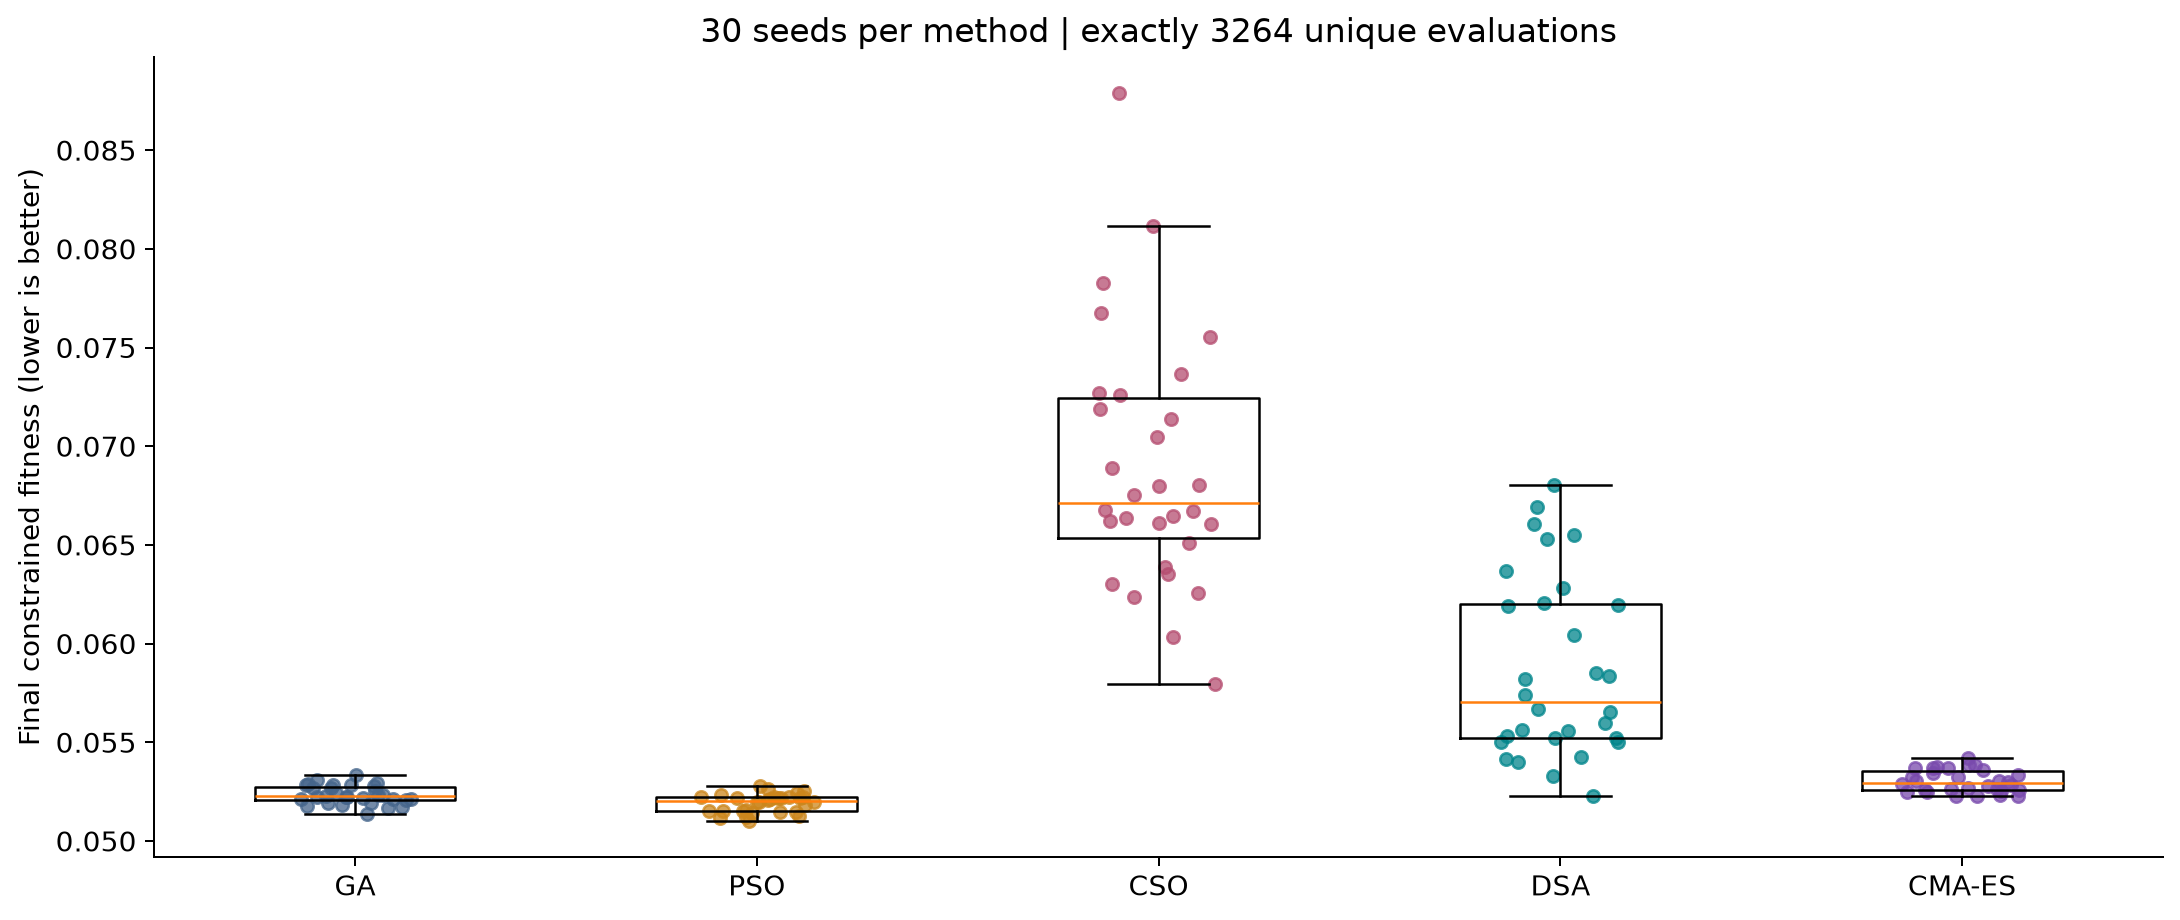

**all work/30 seed equal budget study/results/plots/02_convergence.png**

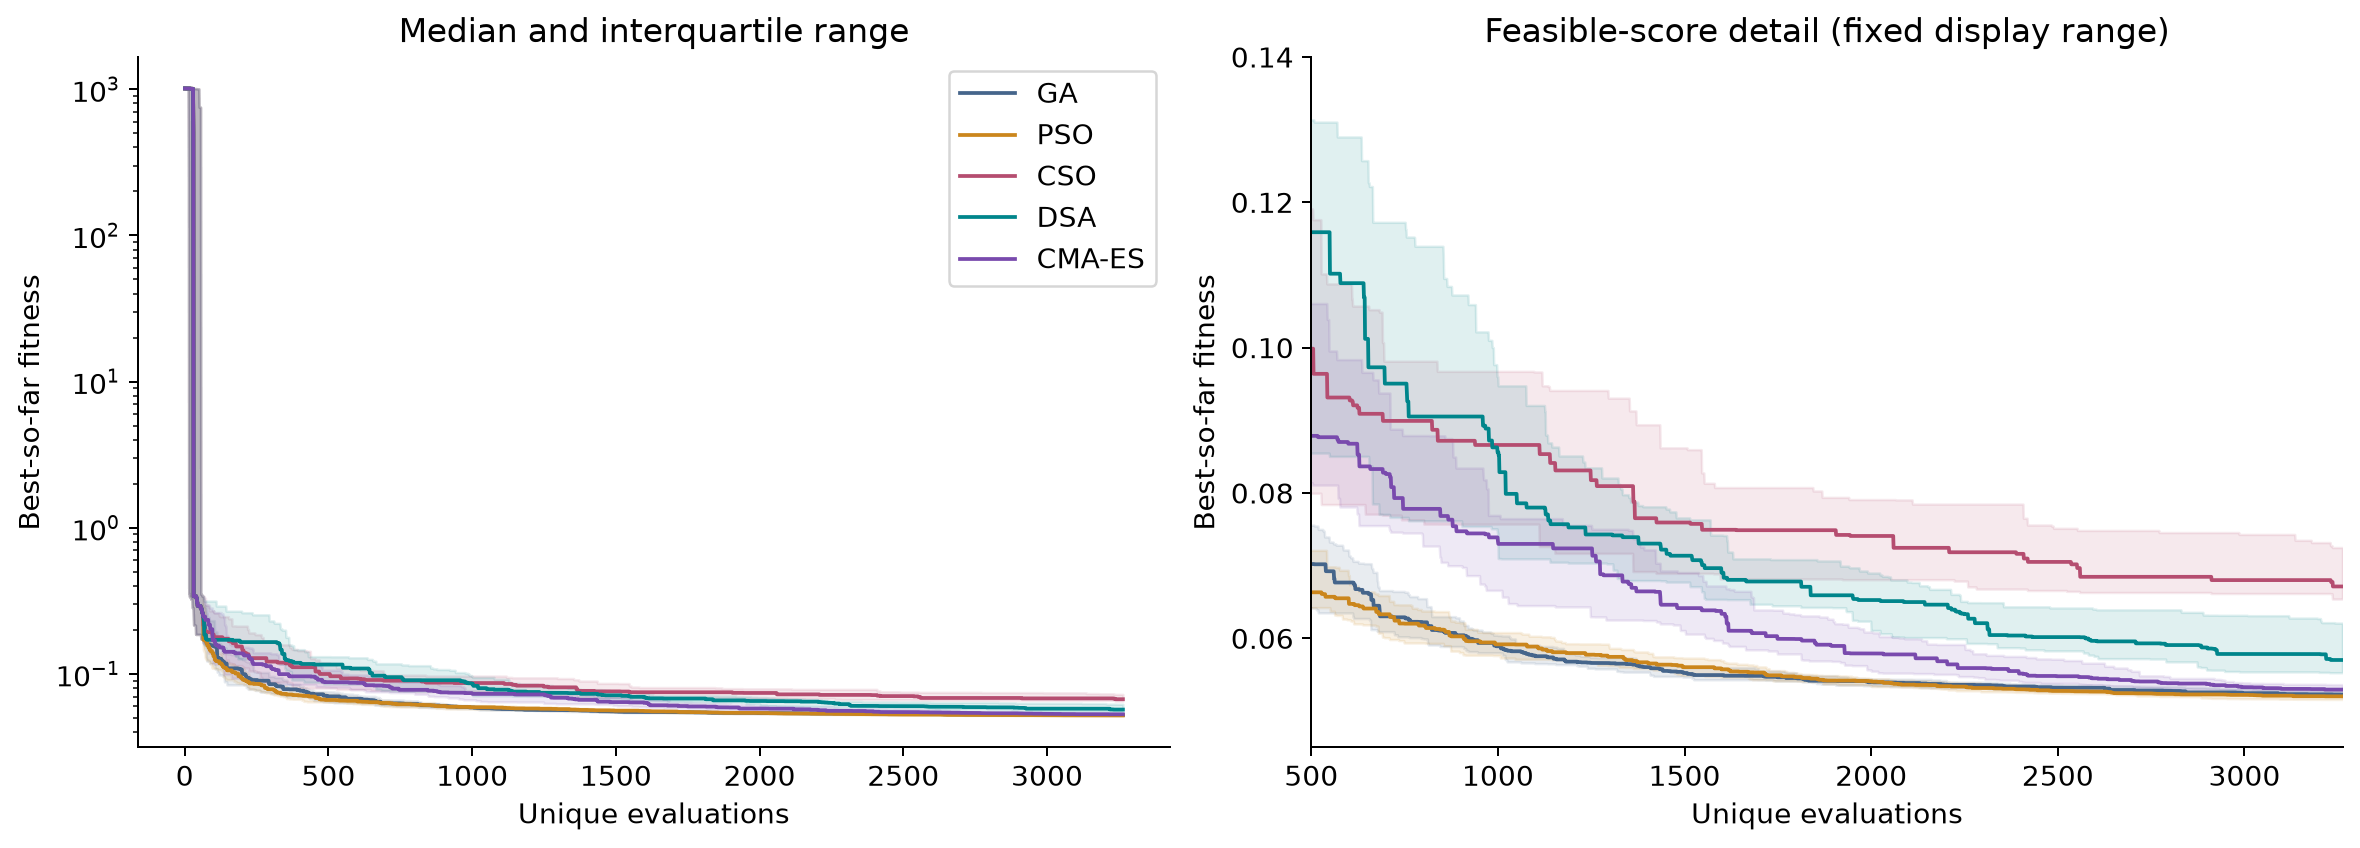

### Files
- [all work/30 seed equal budget study/results/plots/01_fitness_distributions.png](../all%20work/30%20seed%20equal%20budget%20study/results/plots/01_fitness_distributions.png)
- [all work/30 seed equal budget study/results/plots/02_convergence.png](../all%20work/30%20seed%20equal%20budget%20study/results/plots/02_convergence.png)
- [all work/30 seed equal budget study/results/plots/03_robustness.png](../all%20work/30%20seed%20equal%20budget%20study/results/plots/03_robustness.png)
- [all work/30 seed equal budget study/results/plots/04_best_responses.png](../all%20work/30%20seed%20equal%20budget%20study/results/plots/04_best_responses.png)

In [5]:
show_source(BENCHMARK/'benchmark.py','Budget')
show_figures(sorted((BENCHMARK/'results/plots').glob('*.png')),limit=2)
file_links(sorted((BENCHMARK/'results/plots').glob('*.png')))
